In [1]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from prophet import Prophet

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 20)

# pd.options.mode.chained_assignment = None

## Part 1 - Master Data
- Read input data
- Standardize dates
- Match column names
- Combine into one master dataframe of transactions
- Aggregate to weekly sales across SKU, channel, region, size, class, and trim

In [2]:
# 1. Load raw transactional CSVs
dtc = pd.read_csv("data/dtc_web_orders.csv")
dealers = pd.read_csv("data/dealer_orders_export.csv")
pos = pd.read_csv("data/Commercial_PO_Log.csv")

# 2. Standardize DTC Web Orders
dtc["channel"] = "DTC"
dtc["order_date"] = pd.to_datetime(dtc["order_date"])
dtc["week_start_date"] = dtc["order_date"].dt.to_period("W").dt.start_time

dtc_standardized = dtc[[
    "week_start_date", "sku", "class", "size", "trim", 
    "ship_to_state", "qty", "unit_price", "channel"
]].rename(columns={"ship_to_state": "region", "unit_price": "price"})

# 3. Standardize Dealer Orders (Wholesale)
dealers["channel"] = "Dealer Wholesale"
dealers["Order Date"] = pd.to_datetime(dealers["Order Date"])
dealers["week_start_date"] = dealers["Order Date"].dt.to_period("W").dt.start_time

dealers_standardized = dealers[[
    "week_start_date", "SKU", "Class", "Size", "Trim", 
    "State", "Qty", "Wholesale Price", "channel"
]].rename(columns={
    "SKU": "sku", "Class": "class", "Size": "size", "Trim": "trim",
    "State": "region", "Qty": "qty", "Wholesale Price": "price"
})

# 4. Standardize Commercial PO Log (Bulk/Institutional)
pos["channel"] = "Commercial PO"
pos["PO Date"] = pd.to_datetime(pos["PO Date"]) # Handles formats like '06-Sep-2022'
pos["week_start_date"] = pos["PO Date"].dt.to_period("W").dt.start_time

# Note: Commercial PO uses 'Length' and 'Material' instead of Size/Trim, and 'Net Price'
pos_standardized = pos[[
    "week_start_date", "Product", "Class", "Length", "Material", 
    "Units", "Net Price", "channel"
]].rename(columns={
    "Product": "sku", "Class": "class", "Length": "size", "Material": "trim",
    "Units": "qty", "Net Price": "price"
})
# If region/state is missing from PO log, assign a default or handle accordingly
pos_standardized["region"] = "National / Unspecified"

# 5. Union all channels into one master transaction table
master_transactions = pd.concat([
    dtc_standardized, 
    dealers_standardized, 
    pos_standardized
], ignore_index=True)

# 6. Aggregate to the weekly grain required for forecasting
fact_weekly_sales = master_transactions.groupby(
    ["week_start_date", "channel", "region", "sku", "class", "size", "trim"],
    as_index=False
).agg(
    units_sold=("qty", "sum"),
    gross_revenue=("price", lambda x: (x * master_transactions.loc[x.index, "qty"]).sum()),
)

# Calculate weighted average selling price safely
fact_weekly_sales["avg_selling_price"] = fact_weekly_sales["gross_revenue"] / fact_weekly_sales["units_sold"]

#### Add promotions

In [3]:
# 1. Load the promos table
promos = pd.read_csv("data/promos.csv")
promos["Start"] = pd.to_datetime(promos["Start"])
promos["End"] = pd.to_datetime(promos["End"])

# 2. Expand or check promo overlap during aggregation or post-processing
# A clean approach is to attach an `is_promo_active` flag and `promo_discount` to fact_weekly_sales.

def check_promo(row):
    w_date = row["week_start_date"]
    p_class = row["class"].lower() # e.g. 'road' or 'mountain'
    
    for _, promo in promos.iterrows():
        # Check if week falls within promo window
        if promo["Start"] <= w_date <= promo["End"]:
            applies_to = promo["Applies To"].lower()
            # Check if promo applies to all bikes or specific class
            if "all" in applies_to or p_class in applies_to:
                # Return the discount string or a boolean flag
                return True, promo["Discount"]
    return False, "0%"

# Apply the check across your fact table rows
promo_results = fact_weekly_sales.apply(check_promo, axis=1)
fact_weekly_sales["is_promo_active"] = [res[0] for res in promo_results]
fact_weekly_sales["promo_discount"] = [res[1] for res in promo_results]

fact_weekly_sales

,week_start_date,channel,region,sku,class,size,trim,units_sold,gross_revenue,avg_selling_price,is_promo_active,promo_discount
0,2022-09-05,Commercial PO,National / Unspecified,RW-1378,Road,L,Carbon,3,9597,3199.0,False,0%
1,2022-09-05,Commercial PO,National / Unspecified,RW-2984,Road,M,Carbon,9,28791,3199.0,False,0%
2,2022-09-05,Commercial PO,National / Unspecified,RW-3980,Road,S,Carbon,6,19194,3199.0,False,0%
3,2022-09-05,Commercial PO,National / Unspecified,RW-4418,MTB,M,Carbon,6,23514,3919.0,False,0%
4,2022-09-05,Commercial PO,National / Unspecified,RW-6416,MTB,L,Carbon,1,3919,3919.0,False,0%
...,...,...,...,...,...,...,...,...,...,...,...,...
42925,2026-08-31,Dealer Wholesale,VT,RW-1378,Road,L,Carbon,7,20153,2879.0,False,0%
42926,2026-08-31,Dealer Wholesale,VT,RW-4418,MTB,M,Carbon,7,24689,3527.0,False,0%
42927,2026-08-31,Dealer Wholesale,VT,RW-6416,MTB,L,Carbon,10,35270,3527.0,False,0%
42928,2026-08-31,Dealer Wholesale,VT,RW-9835,Road,M,Base,3,4101,1367.0,False,0%


In [4]:
# fact_weekly_sales[['week_start_date', 'sku', 'units_sold', 'gross_revenue']].groupby(
#     ["week_start_date","sku"], as_index=False).sum()

## Part 2 - Sales Forecast
### 2a. Decompose into observed, trend, seasonality, and residuals

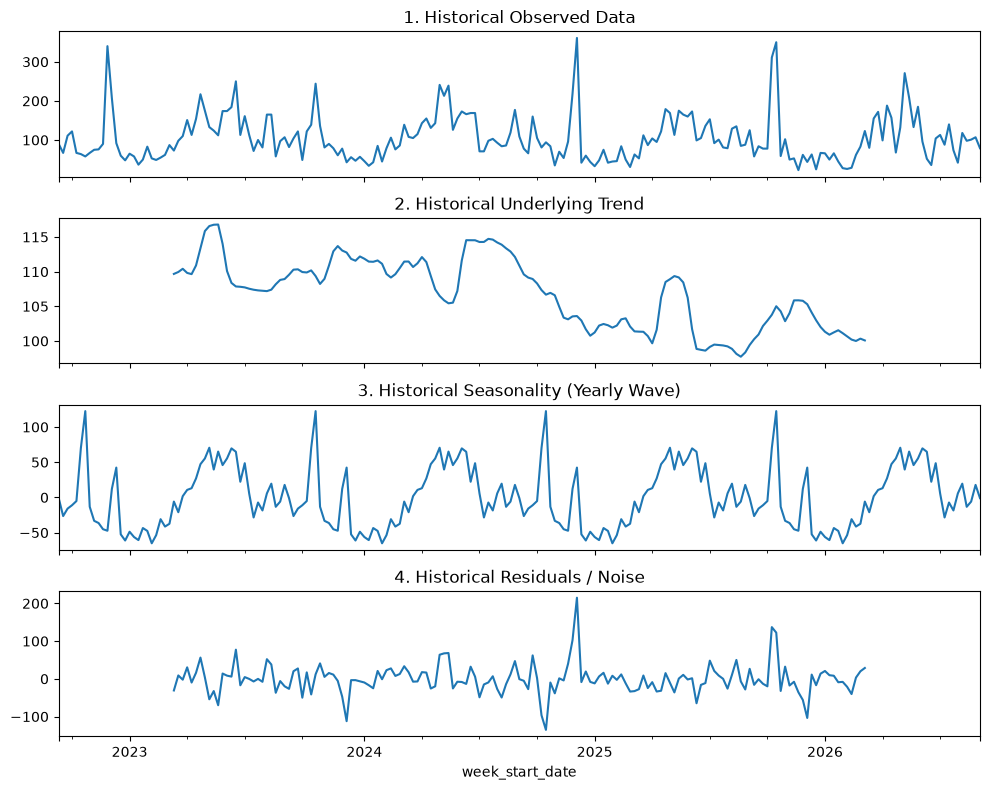

In [5]:
# 1. Assume `fact_weekly_sales` is your master table from Part 1
# Let's filter for just one specific SKU to make the math clean and visible
sku_sample = "RW-3980"  # Replace with any SKU from your dataset
df_sku = fact_weekly_sales[fact_weekly_sales["sku"] == sku_sample].copy()

# 2. Sort by week and set the week_start_date as the dataframe index
df_sku = df_sku.sort_values("week_start_date")
df_sku = df_sku.set_index("week_start_date")

# 3. Resample to ensure a continuous weekly timeline (filling missing weeks with 0 units sold)
weekly_series = df_sku["units_sold"].resample("W").sum().fillna(0)

def plot_historical_decomposition(weekly_series):
    """Runs and plots statsmodels seasonal decomposition on historical weekly sales."""
    fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(10, 8), sharex=True)

    # Decompose history
    decomp = seasonal_decompose(weekly_series, model="additive", period=52)

    decomp.observed.plot(ax=ax1, title="1. Historical Observed Data")
    decomp.trend.plot(ax=ax2, title="2. Historical Underlying Trend")
    decomp.seasonal.plot(ax=ax3, title="3. Historical Seasonality (Yearly Wave)")
    decomp.resid.plot(ax=ax4, title="4. Historical Residuals / Noise")

    plt.tight_layout()
    plt.show()
    
plot_historical_decomposition(weekly_series)

### 2b. Forecast the next two years

In [6]:
def generate_all_forecasts(fact_weekly_sales, periods_ahead=104):
    """Loops through every unique combination of SKU, Channel, and attributes,

    generates a 2-year baseline forecast for each, and combines them into one master table.
    """
    all_forecasts = []

    # Group by the distinct dimensions that make up each unique product/channel line
    group_cols = ["sku", "channel", "class", "size", "trim", "region"]

    for group_keys, group_df in fact_weekly_sales.groupby(group_cols):
        # 1. Sort and set index
        df_sorted = group_df.sort_values("week_start_date")
        df_set = df_sorted.set_index("week_start_date")

        # 2. Resample to continuous weekly timeline
        weekly_series = df_set["units_sold"].resample("W").sum().fillna(0)

        # Skip if there's no sales history at all for this group
        if weekly_series.sum() == 0:
            continue

        # 3. Create future dates
        last_date = weekly_series.index.max()
        future_dates = pd.date_range(
            start=last_date + pd.Timedelta(weeks=1),
            periods=periods_ahead,
            freq="W",
        )

        # 4. Project baseline trend and seasonality
        recent_trend_estimate = weekly_series.tail(12).mean()
        last_year_seasonality = weekly_series[-52:].values
        # Handle case where group has less than 52 weeks of history
        if len(last_year_seasonality) < 52:
            last_year_seasonality = np.pad(
                last_year_seasonality,
                (52 - len(last_year_seasonality), 0),
                mode="edge",
            )

        projected_seasonality = np.tile(last_year_seasonality, 2)[
            :periods_ahead
        ]

        # 5. Build forecast dataframe for this specific group
        sku, channel, p_class, size, trim, region = group_keys
        forecast_df = pd.DataFrame(
            {
                "week_start_date": future_dates,
                "sku": sku,
                "channel": channel,
                "class": p_class,
                "size": size,
                "trim": trim,
                "region": region,
                "yhat": recent_trend_estimate
                + (projected_seasonality - projected_seasonality.mean()),
            }
        )

        # Ensure no negative forecasts
        forecast_df["yhat"] = forecast_df["yhat"].clip(lower=0)
        all_forecasts.append(forecast_df)

    # Combine all individual group forecasts into one massive master forecast table
    master_forecast = pd.concat(all_forecasts, ignore_index=True)
    return master_forecast


# Run it across your entire dataset!
base_forecast_df = generate_all_forecasts(fact_weekly_sales)
base_forecast_df

,week_start_date,sku,channel,class,size,trim,region,yhat
0,2026-09-13,RW-1378,Commercial PO,Road,L,Carbon,National / Unspecified,8.769231
1,2026-09-20,RW-1378,Commercial PO,Road,L,Carbon,National / Unspecified,10.769231
2,2026-09-27,RW-1378,Commercial PO,Road,L,Carbon,National / Unspecified,5.769231
3,2026-10-04,RW-1378,Commercial PO,Road,L,Carbon,National / Unspecified,7.769231
4,2026-10-11,RW-1378,Commercial PO,Road,L,Carbon,National / Unspecified,8.769231
...,...,...,...,...,...,...,...,...
42635,2028-07-23,RW-9901,Dealer Wholesale,MTB,L,Base,WA,0.000000
42636,2028-07-30,RW-9901,Dealer Wholesale,MTB,L,Base,WA,0.000000
42637,2028-08-06,RW-9901,Dealer Wholesale,MTB,L,Base,WA,0.000000
42638,2028-08-13,RW-9901,Dealer Wholesale,MTB,L,Base,WA,0.000000


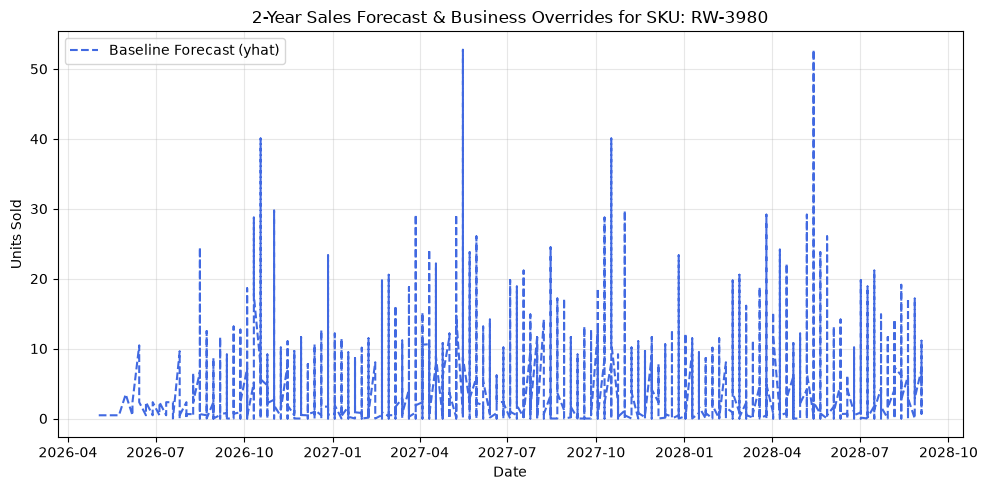

In [7]:
def plot_forecast(forecast_df, sku_id = 'RW-3980'):
    """Plots the projected baseline forecast alongside any applied business overrides for a specific SKU."""
    df = forecast_df[forecast_df["sku"] == sku_id].sort_values("week_start_date")

    if df.empty:
        print(f"No forecast data found for SKU: {sku_id}")
        return

    fig, ax = plt.subplots(figsize=(10, 5))

    # Plot baseline forecast (yhat)
    ax.plot(
        df["week_start_date"],
        df["yhat"],
        label="Baseline Forecast (yhat)",
        color="royalblue",
        linestyle="--",
    )

    # If overrides were applied, plot the adjusted forecast as well
    if "yhat_adjusted" in df.columns:
        ax.plot(
            df["week_start_date"],
            df["yhat_adjusted"],
            label="Adjusted Forecast (with Overrides)",
            color="forestgreen",
            linewidth=2,
        )

    ax.set_title(f"2-Year Sales Forecast & Business Overrides for SKU: {sku_id}")
    ax.set_xlabel("Date")
    ax.set_ylabel("Units Sold")
    ax.legend()
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()
    
# Plot example: SKU RW-3980
plot_forecast(base_forecast_df, 'RW-3980')

### 2x. Prophet Forecasting

19:52:32 - cmdstanpy - INFO - Chain [1] start processing
19:52:32 - cmdstanpy - INFO - Chain [1] done processing


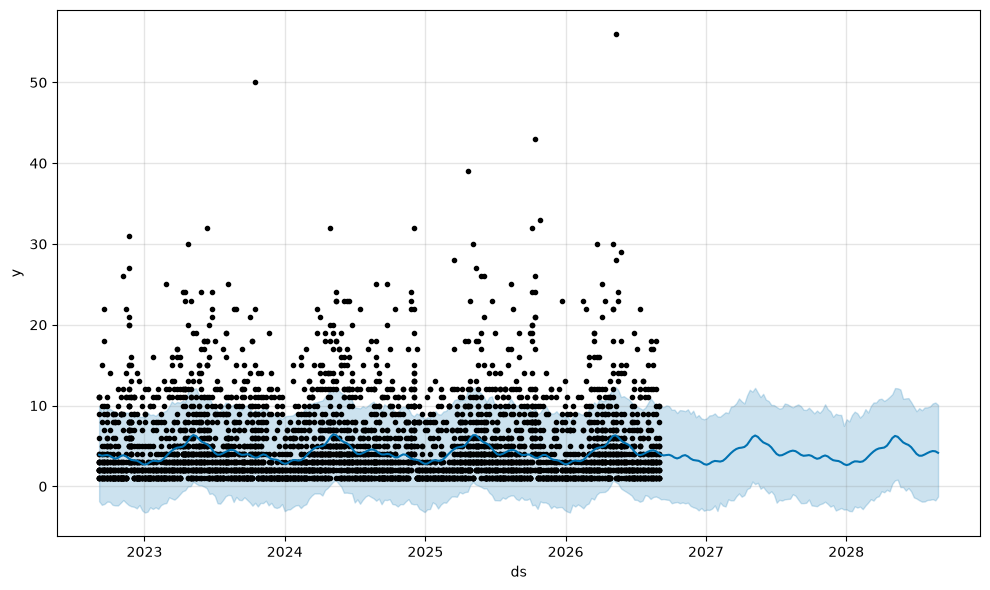

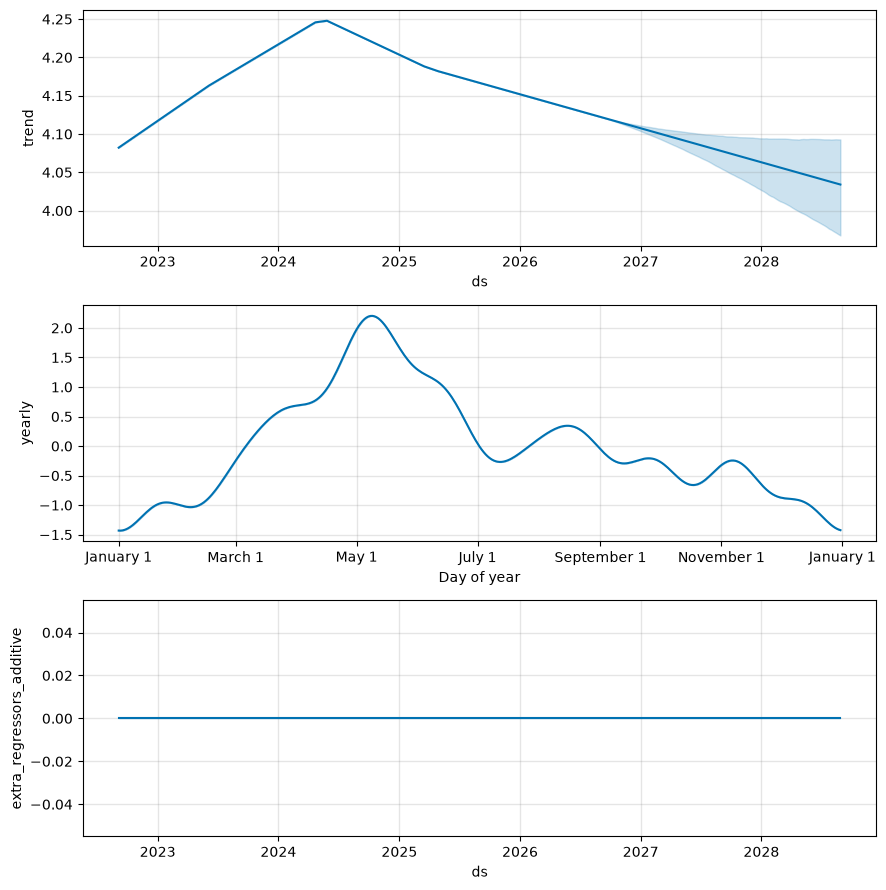

In [8]:
# 1. Prepare data for a single SKU from your master weekly table
sku_sample = "RW-3980"
df_sku = fact_weekly_sales[fact_weekly_sales["sku"] == sku_sample].copy()

# Prophet strictly requires columns named 'ds' (date) and 'y' (value)
df_prophet = df_sku[["week_start_date", "units_sold", "is_promo_active"]].rename(
    columns={"week_start_date": "ds", "units_sold": "y"}
)

# 2. Initialize and configure the Prophet model
# We tell it we have yearly seasonality (52-week cycle)
model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,  # Since our data is already aggregated to weekly totals
    daily_seasonality=False,
)

# 3. Add your promotional flag as an extra regressor (external feature)
model.add_regressor("is_promo_active")

# 4. Fit the model on historical data
model.fit(df_prophet)

# 5. Create a future dataframe for the next 2 years (104 weeks)
future = model.make_future_dataframe(periods=104, freq="W")

# Note: For future weeks, you would ideally populate `is_promo_active` based on your planned 
# marketing schedule. For a baseline projection, we can set future promo flags to False (0).
future["is_promo_active"] = 0
# (If you have future promo dates planned, you can map them onto `future` here!)

# 6. Generate the forecast!
forecast = model.predict(future)

# Plot the overall forecast (showing history dots + future line + uncertainty intervals)
fig1 = model.plot(forecast)

# Plot the individual components (Trend breakdown and Yearly Seasonality wave)
fig2 = model.plot_components(forecast)

In [9]:
def generate_all_prophet_forecasts_with_models(fact_weekly_sales, periods_ahead=104):
    """
    Loops through every unique SKU, trains a Prophet model on its weekly data,
    saves the model object, and returns both the master forecast table and the models dictionary.
    """
    all_forecasts = []
    models_dict = {}  # Store trained Prophet models keyed by SKU
    
    # Group strictly by SKU
    group_cols = "sku"
    
    for sku, group_df in fact_weekly_sales.groupby(group_cols):
        
        # 1. Sort and prepare dataframe for Prophet ('ds', 'y', 'is_promo_active')
        df_sorted = group_df.sort_values("week_start_date")
        df_prophet = df_sorted[["week_start_date", "units_sold", "is_promo_active"]].rename(
            columns={"week_start_date": "ds", "units_sold": "y"}
        )
        
        # Resample to continuous weekly timeline and fill missing weeks with zeros
        df_prophet = df_prophet.set_index("ds").resample("W").agg({
            "y": "sum",
            "is_promo_active": "max"
        }).fillna({"y": 0, "is_promo_active": 0}).reset_index()
        
        # Skip if there's no sales history at all
        if df_prophet["y"].sum() == 0:
            continue
            
        # 2. Initialize and fit Prophet model
        model = Prophet(
            yearly_seasonality=True,
            weekly_seasonality=False,
            daily_seasonality=False
        )
        model.add_regressor("is_promo_active")
        
        try:
            model.fit(df_prophet)
            models_dict[sku] = model  # Save the trained model mapped to its SKU
        except Exception as e:
            print(f"Skipping SKU {sku} due to fitting error: {e}")
            continue
            
        # 3. Create future dataframe for the next 2 years (104 weeks)
        future = model.make_future_dataframe(periods=periods_ahead, freq="W")
        future["is_promo_active"] = 0  # Default future promo flag to 0
        forecast = model.predict(future)
        
        # 4. Attach SKU identifier and clean up columns
        forecast["sku"] = sku
        
        clean_forecast = forecast[["ds", "sku", "yhat", "yhat_lower", "yhat_upper"]]
        clean_forecast["yhat"] = clean_forecast["yhat"].clip(lower=0)
        clean_forecast["yhat_lower"] = clean_forecast["yhat_lower"].clip(lower=0)
        clean_forecast["yhat_upper"] = clean_forecast["yhat_upper"].clip(lower=0)
        
        all_forecasts.append(clean_forecast)
        
    # Combine everything into one master table
    master_prophet_df = pd.concat(all_forecasts, ignore_index=True)
    
    return master_prophet_df, models_dict

# --- How you call it in your notebook ---
master_prophet_forecasts, sku_models_dict = generate_all_prophet_forecasts_with_models(fact_weekly_sales)
master_prophet_forecasts

19:52:32 - cmdstanpy - INFO - Chain [1] start processing
19:52:32 - cmdstanpy - INFO - Chain [1] done processing
19:52:32 - cmdstanpy - INFO - Chain [1] start processing
19:52:32 - cmdstanpy - INFO - Chain [1] done processing
19:52:33 - cmdstanpy - INFO - Chain [1] start processing
19:52:33 - cmdstanpy - INFO - Chain [1] done processing
19:52:33 - cmdstanpy - INFO - Chain [1] start processing
19:52:33 - cmdstanpy - INFO - Chain [1] done processing
19:52:33 - cmdstanpy - INFO - Chain [1] start processing
19:52:33 - cmdstanpy - INFO - Chain [1] done processing
19:52:33 - cmdstanpy - INFO - Chain [1] start processing
19:52:33 - cmdstanpy - INFO - Chain [1] done processing
19:52:33 - cmdstanpy - INFO - Chain [1] start processing
19:52:33 - cmdstanpy - INFO - Chain [1] done processing
19:52:33 - cmdstanpy - INFO - Chain [1] start processing
19:52:33 - cmdstanpy - INFO - Chain [1] done processing
19:52:33 - cmdstanpy - INFO - Chain [1] start processing
19:52:33 - cmdstanpy - INFO - Chain [1]

,ds,sku,yhat,yhat_lower,yhat_upper
0,2022-09-11,RW-1378,44.990731,20.952071,70.547974
1,2022-09-18,RW-1378,42.552022,16.022204,66.206433
2,2022-09-25,RW-1378,42.309651,16.592232,66.336100
3,2022-10-02,RW-1378,42.542234,18.328071,67.127761
4,2022-10-09,RW-1378,41.098527,16.208554,66.032749
...,...,...,...,...,...
3125,2028-08-06,RW-9901,100.717760,34.597333,162.823444
3126,2028-08-13,RW-9901,91.230646,22.524251,156.009543
3127,2028-08-20,RW-9901,91.828679,28.406321,158.786628
3128,2028-08-27,RW-9901,97.239451,29.363851,161.882645


### Visualizations

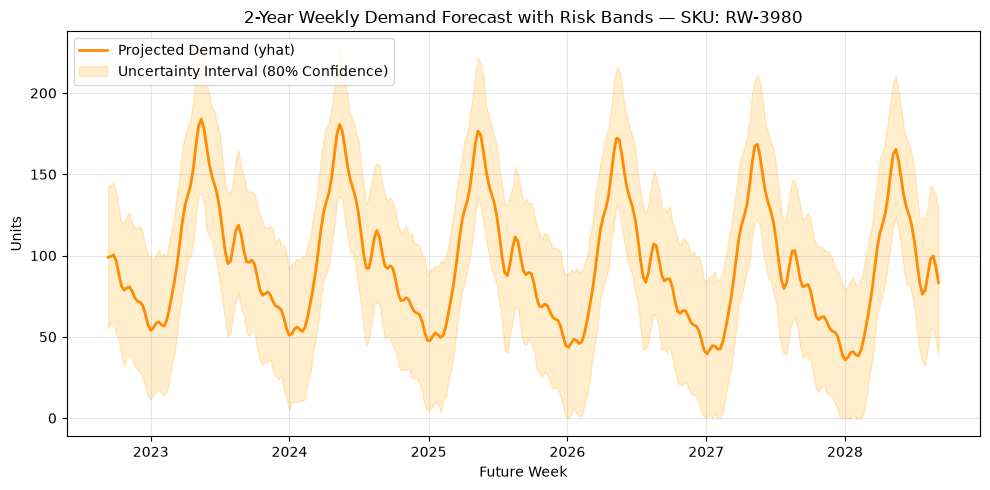

In [11]:
def plot_prophet_forecast_card(master_df, sku_id):
    
    df = master_df[master_df["sku"] == sku_id].sort_values("ds")

    fig, ax = plt.subplots(figsize=(10, 5))

    # Plot the main forecast line
    ax.plot(
      df["ds"],
      df["yhat"],
      label="Projected Demand (yhat)",
      color="darkorange",
      lw=2,
    )

    # Plot the uncertainty interval (Risk floor and ceiling)
    ax.fill_between(
      df["ds"],
      df["yhat_lower"],
      df["yhat_upper"],
      color="orange",
      alpha=0.2,
      label="Uncertainty Interval (80% Confidence)",
    )

    ax.set_title(
      f"2-Year Weekly Demand Forecast with Risk Bands — SKU: {sku_id}"
    )
    ax.set_xlabel("Future Week")
    ax.set_ylabel("Units")
    ax.legend(loc="upper left")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


plot_prophet_forecast_card(master_prophet_forecasts, "RW-3980")

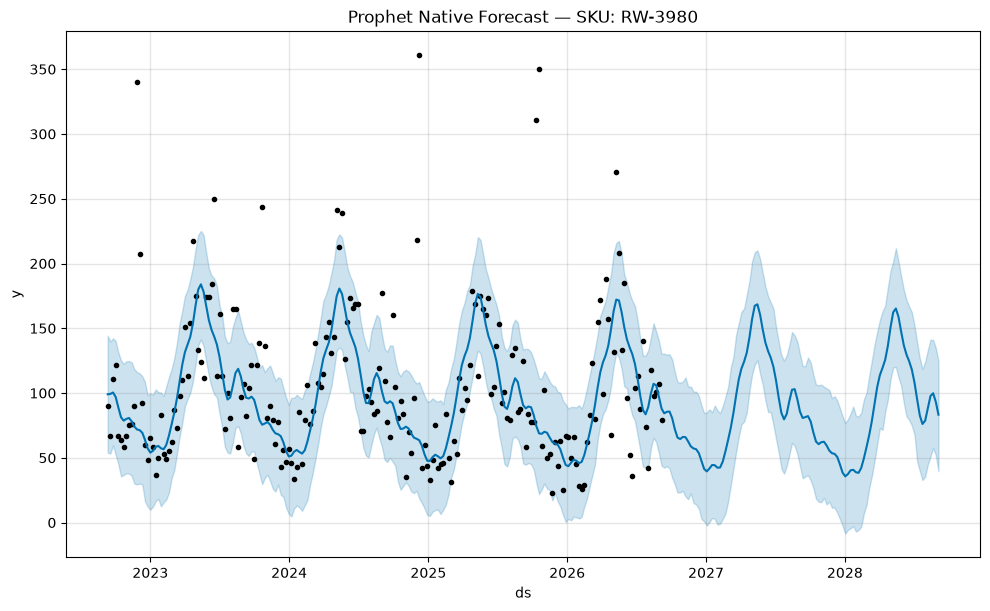

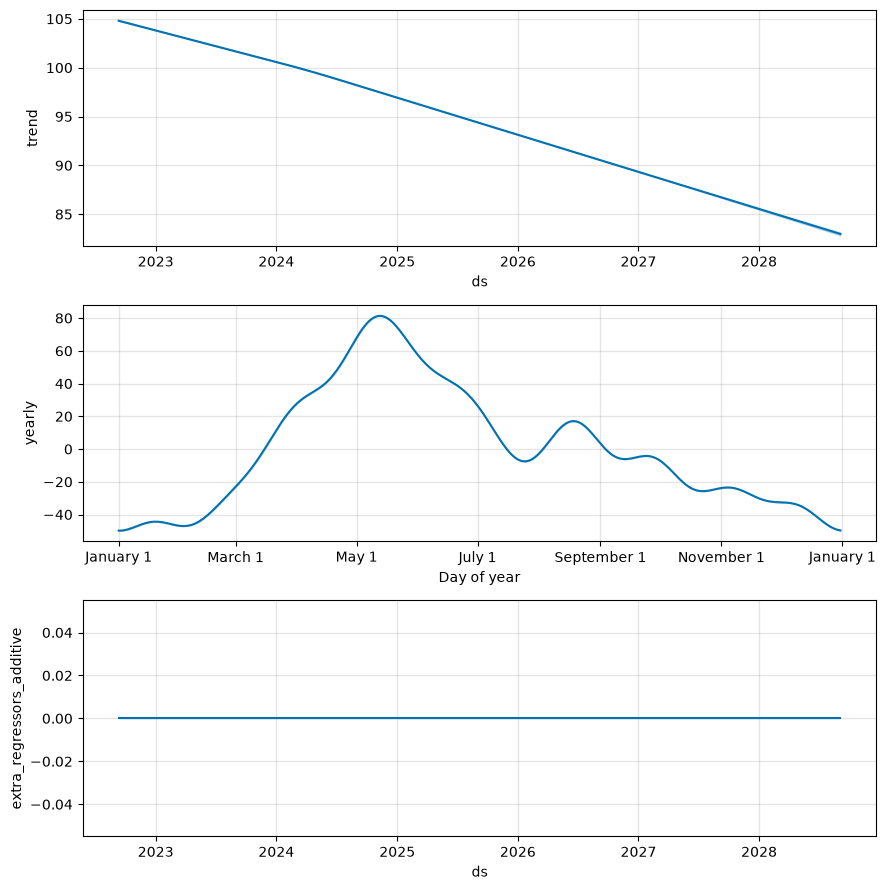

In [12]:
def plot_prophet_native(sku_models_dict, sku_id):
    """
    Safely generates and displays Prophet's native plot for a given SKU 
    using the saved model dictionary.
    """
    if sku_id not in sku_models_dict:
        print(f"Model for SKU '{sku_id}' not found in dictionary.")
        return
        
    model = sku_models_dict[sku_id]
    
    # 1. Let the model create its own standard future dataframe & predict fresh
    future = model.make_future_dataframe(periods=104, freq="W")
    future["is_promo_active"] = 0  # Default future promo flag
    forecast_native = model.predict(future)
    
    # 2. Use Prophet's native plot method safely
    fig1 = model.plot(forecast_native)
    plt.title(f"Prophet Native Forecast — SKU: {sku_id}")
    plt.show()
    
    # 3. Plot components (Trend & Seasonality)
    fig2 = model.plot_components(forecast_native)
    plt.show()

# --- How to use it ---
plot_prophet_native(sku_models_dict, "RW-3980")

### 2c. Add controllable adjustments/business overrides

In [14]:
# # Pull the model and its corresponding forecast dataframe for a specific SKU
# sku_to_plot = "RW-3980"
# target_model = models_dict[sku_to_plot]
# target_forecast = master_prophet_forecasts[
#     master_prophet_forecasts["sku"] == sku_to_plot
# ]

# # Use Prophet's built-in native plots
# fig1 = target_model.plot(target_forecast)
# plt.title(f"Prophet Native Forecast - SKU: {sku_to_plot}")
# plt.show()

# fig2 = target_model.plot_components(target_forecast)
# plt.show()

In [22]:
def apply_business_overrides(forecast_df, q4_bump_pct=0.10, targeted_injections=None):
    """
    Applies post-processing business adjustments on top of the base forecast.
    forecast_df must have columns:
    ['week_start_date', 'sku', 'class', 'size', 'trim', 'channel', 'yhat' (forecasted units)]
    """
    df = forecast_df.copy()
    
    # 1. Apply Global Q4 Bump (October, November, December)
    is_q4 = df['ds'].dt.month.isin([10, 11, 12])
    df.loc[is_q4, 'yhat_adjusted'] = df.loc[is_q4, 'yhat'] * (1 + q4_bump_pct)
    df.loc[~is_q4, 'yhat_adjusted'] = df.loc[~is_q4, 'yhat']
    
    # Track which rows got the override for transparency in reporting
    df['override_applied'] = is_q4
    df['override_description'] = "Base Forecast"
    df.loc[is_q4, 'override_description'] = f"Q4 Bump (+{int(q4_bump_pct*100)}%)"

    # 2. Apply Targeted Injections (e.g., +2000 MTB Carbon L across July weeks)
    if targeted_injections:
        for inj in targeted_injections:
            # Match conditions (class, trim, size, month)
            mask = (
                (df['class'].str.lower() == inj['class'].lower()) &
                (df['trim'].str.lower() == inj['trim'].lower()) &
                (df['size'].str.lower() == inj['size'].lower()) &
                (df['ds'].dt.month == inj['month'])
            )
            # Distribute the units evenly across the weeks of that month
            matching_weeks = mask.sum()
            if matching_weeks > 0:
                units_per_week = inj['extra_units'] / matching_weeks
                df.loc[mask, 'yhat_adjusted'] += units_per_week
                df.loc[mask, 'override_applied'] = True
                df.loc[mask, 'override_description'] += f" + Targeted ({inj['extra_units']} units)"

    return df

# Example usage:
targeted_events = [{'class': 'mountain', 'trim': 'carbon', 'size': 'l', 'month': 7, 'extra_units': 2000}]
final_forecast = apply_business_overrides(master_prophet_forecasts, q4_bump_pct=0.10,
                                          targeted_injections=targeted_events)
final_forecast

KeyError: 'class'

In [23]:
def apply_business_overrides(forecast_df, q4_bump_pct=0.10, targeted_injections=None):
    """
    Applies business-driven overrides to the simplified master forecast table.
    - q4_bump_pct: Percentage increase applied globally to October, November, and December.
    - targeted_injections: List of dicts specifying extra units for a specific SKU and month.
      Example: [{'sku': 'RW-3980', 'month': 7, 'extra_units': 500}]
    """
    df = forecast_df.copy()
    
    # 1. Initialize yhat_adjusted as a copy of the base statistical forecast
    df["yhat_adjusted"] = df["yhat"]
    
    # 2. Apply global Q4 seasonal bump (Oct, Nov, Dec)
    if q4_bump_pct > 0:
        q4_mask = df["ds"].dt.month.isin([10, 11, 12])
        df.loc[q4_mask, "yhat_adjusted"] *= (1 + q4_bump_pct)
        
    # 3. Apply SKU-specific targeted injections if any are provided
    if targeted_injections:
        for injection in targeted_injections:
            target_sku = injection.get("sku")
            target_month = injection.get("month")
            extra_units = injection.get("extra_units", 0)
            
            # Match by SKU and specific calendar month across the timeline
            mask = (df["sku"] == target_sku) & (df["ds"].dt.month == target_month)
            df.loc[mask, "yhat_adjusted"] += extra_units
            
    # Ensure adjusted forecasts never dip below zero
    df["yhat_adjusted"] = df["yhat_adjusted"].clip(lower=0)
    
    return df

In [25]:
# Define SKU-specific overrides (e.g., adding 500 units to RW-3980 every July)
custom_injections = [
    {'sku': 'RW-3980', 'month': 7, 'extra_units': 500}
]

# Run it on your simplified master forecast table
final_master_forecast = apply_business_overrides(
    master_prophet_forecasts, 
    q4_bump_pct=0.10,            # 10% holiday bump
    targeted_injections=custom_injections
)
final_master_forecast

,ds,sku,yhat,yhat_lower,yhat_upper,yhat_adjusted
0,2022-09-11,RW-1378,44.990731,20.952071,70.547974,44.990731
1,2022-09-18,RW-1378,42.552022,16.022204,66.206433,42.552022
2,2022-09-25,RW-1378,42.309651,16.592232,66.336100,42.309651
3,2022-10-02,RW-1378,42.542234,18.328071,67.127761,46.796458
4,2022-10-09,RW-1378,41.098527,16.208554,66.032749,45.208380
...,...,...,...,...,...,...
3125,2028-08-06,RW-9901,100.717760,34.597333,162.823444,100.717760
3126,2028-08-13,RW-9901,91.230646,22.524251,156.009543,91.230646
3127,2028-08-20,RW-9901,91.828679,28.406321,158.786628,91.828679
3128,2028-08-27,RW-9901,97.239451,29.363851,161.882645,97.239451


### Save

In [26]:
final_master_forecast.to_csv('data/redwheel_final_sales_forecast.csv')